# Support Vector Machines – forelesning 1: Python-kode med forklaringer

Dette skriptet er en Python-versjon av R-skriptet til forelesning 1.
Det er skrevet i *percent*-format: hver `# %%` starter en ny kodecelle, og `# %% [markdown]` starter en tekstcelle.
I VS Code, Spyder eller PyCharm kan du kjøre cellene én og én.
Du kan også kjøre hele filen som et vanlig skript med `python svm_forelesning_1.py`, eller åpne notebook-versjonen (`.ipynb`) i Jupyter.

**Om tallene:** Python og R bruker ulike tilfeldighetsgeneratorer.
Selv med samme oppskrift blir de simulerte dataene derfor ikke identiske, og tallene her er ikke de samme som i R-versjonen.
Frøene er valgt slik at mønsteret er det samme, og konklusjonene gjelder like godt.
Selve SVM-algoritmen er den samme: både `e1071` i R og `scikit-learn` i Python bruker biblioteket *libsvm* under panseret.

**Fra R til Python – de viktigste oversettelsene:**

| R (`e1071`) | Python (`scikit-learn`) |
|:--|:--|
| `svm(..., kernel = "linear", cost = C)` | `SVC(kernel="linear", C=C)` |
| `mod$SV` | `mod.support_vectors_` |
| `mod$coefs` | `mod.dual_coef_` |
| `-mod$rho` | `mod.intercept_` |
| `mod$index` | `mod.support_` (merk: teller fra 0) |
| `mod$tot.nSV` | `mod.n_support_.sum()` |
| `scale = TRUE` | `StandardScaler()` i en `Pipeline` |
| `tune(...)` | `GridSearchCV(...)` |

## 1. Pakker og simulerte lånedata

Vi trenger fire pakker. Mangler noen, installer dem med `pip install numpy pandas matplotlib scikit-learn`.

- `numpy`: tall og matriser,
- `pandas`: datatabeller (tilsvarer `data.frame` i R),
- `matplotlib`: figurer,
- `scikit-learn` (importeres som `sklearn`): maskinlæringsmodellene.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold

Vi lager 100 tenkte lånesøknader.
Fordi dataene er simulert, vet vi hvordan sammenhengen egentlig ser ut, og vi kan sjekke om modellen finner den.

I Python lager vi en egen tilfeldighetsgenerator med et frø, i stedet for `set.seed()` som i R.

In [2]:
rng = np.random.default_rng(69)   # Generator med frø: samme frø gir samme data hver gang
n = 100                           # Antall lånesøknader

# Inntekt i 1000 kr: normalfordelt rundt 550 (dvs. 550 000 kr) med standardavvik 150
inntekt = np.round(rng.normal(loc=550, scale=150, size=n))

# Gjeldsgrad (gjeld delt på inntekt): rundt 2,5. np.maximum(..., 0.2) hindrer urimelige negative verdier
gjeldsgrad = np.round(np.maximum(rng.normal(loc=2.5, scale=1, size=n), 0.2), 2)


def standardiser(v):
    """Trekk fra gjennomsnittet og del på standardavviket, som scale() i R."""
    return (v - v.mean()) / v.std(ddof=1)   # ddof=1 gir samme standardavvik som sd() i R


# Uobservert «risiko»: lav inntekt og høy gjeldsgrad øker risikoen.
# Vi standardiserer, slik at de to variablene veier omtrent likt.
# rng.normal(0, 0.8, n) er støy: forhold vi ikke observerer. Den gjør at klassene overlapper.
risiko = -standardiser(inntekt) + 0.9 * standardiser(gjeldsgrad) + rng.normal(0, 0.8, n)

# Klassen: mislighold hvis risikoen er over 0,4.
# I Python trenger vi ikke factor(): SVC() forstår at tekstverdier betyr klassifikasjon.
y = np.where(risiko > 0.4, "Mislighold", "Ingen mislighold")

dat_laan = pd.DataFrame({"inntekt": inntekt, "gjeldsgrad": gjeldsgrad, "y": y})

print(dat_laan.describe().round(2))   # Oppsummering av de numeriske variablene
print()
print(dat_laan["y"].value_counts())   # Antall i hver klasse

       inntekt  gjeldsgrad
count   100.00      100.00
mean    557.28        2.36
std     136.75        1.04
min     130.00        0.20
25%     477.75        1.69
50%     571.00        2.42
75%     644.50        3.26
max     949.00        4.31

y
Ingen mislighold    60
Mislighold          40
Name: count, dtype: int64


**Slik leser du output:**
`describe()` gir antall (`count`), gjennomsnitt (`mean`), standardavvik (`std`), minimum, kvartiler og maksimum.
Inntekt går fra 130 til 949 (tusen kr) med standardavvik rundt 137, mens gjeldsgrad går fra 0,2 til 4,3 med standardavvik rundt 1.
Variablene er altså målt på helt ulike skalaer.
Under `y` ser vi at 60 søknader er «Ingen mislighold» og 40 er «Mislighold».

Merk deg tallet 60: en «modell» som alltid gjetter «Ingen mislighold», treffer 60 % av gangene.
En SVC må gjøre det klart bedre enn dette for å være nyttig.

## 2. Standardisering og en egen plottefunksjon

For å kunne *se* marginen standardiserer vi begge prediktorene, slik at de får gjennomsnitt 0 og standardavvik 1.
Da betyr én enhet på hver akse «ett standardavvik», og avstander i plottet blir sammenlignbare.
Her standardiserer vi hele datasettet på én gang; det er greit for en illustrasjon, men ikke når vi skal velge modell (se del 4).

`scikit-learn` vil ha prediktorene som en matrise `X` (én rad per observasjon, én kolonne per prediktor) og klassene som en vektor `y`.
Det tilsvarer formelen `y ~ inntekt + gjeldsgrad` i R.

In [3]:
X_std = np.column_stack([standardiser(inntekt), standardiser(gjeldsgrad)])   # 100 x 2-matrise

Vi lager vår egen plottefunksjon `tegn_svc()`, som tegner punktene, beslutningsgrensen, marginene og støttevektorene.

Koeffisientvektoren er en vektet sum av støttevektorene: $\boldsymbol\beta = \sum_{i \in \mathcal S} \alpha_i x_i$.
I `scikit-learn` ligger

- støttevektorene i `mod.support_vectors_` (én rad per støttevektor),
- vektene $\alpha_i$ i `mod.dual_coef_`,
- konstantleddet $\beta_0$ i `mod.intercept_`.

For lineær kjerne finnes $\boldsymbol\beta$ også ferdig utregnet i `mod.coef_`, men vi regner den ut selv for å se sammenhengen.
Dette kommer vi tilbake til i forelesning 2.

For å tegne linjen der $f(x) = k$, løser vi $\beta_0 + \beta_1 x_1 + \beta_2 x_2 = k$ med hensyn på $x_2$:
$$x_2 = \frac{k - \beta_0}{\beta_2} - \frac{\beta_1}{\beta_2}\,x_1.$$
Med $k = 0$ får vi beslutningsgrensen, og med $k = \pm 1$ får vi de to marginene.

**Fortegnet:** I `scikit-learn` sorteres klassene alfabetisk i `mod.classes_`.
Positiv $f(x)$ betyr den *andre* klassen, her «Mislighold».

In [4]:
def tegn_svc(mod, X, y, ax, tittel=""):
    # Koeffisienter: beta = sum_i alpha_i * x_i, regnet ut som matriseprodukt
    beta = (mod.dual_coef_ @ mod.support_vectors_).ravel()
    beta0 = mod.intercept_[0]

    # Farge etter faktisk klasse
    farge = np.where(y == "Mislighold", "#cc583b", "#276ca6")
    ax.scatter(X[:, 0], X[:, 1], c=farge, s=20)

    # Tre linjer: f(x) = -1 og f(x) = +1 (stiplet, marginene) og f(x) = 0 (heltrukket, grensen)
    for k in (-1, 0, 1):
        ax.axline((0, (k - beta0) / beta[1]),     # punktet der linjen krysser y-aksen
                  slope=-beta[0] / beta[1],       # stigningstall
                  color="black",
                  linestyle="-" if k == 0 else "--",
                  linewidth=2 if k == 0 else 1)

    # mod.support_ er radnumrene til støttevektorene. Vi tegner en ring rundt hver av dem
    sv = mod.support_
    ax.scatter(X[sv, 0], X[sv, 1], s=110, facecolors="none", edgecolors="black", linewidths=0.8)

    # Forklaring (legend) med én prikk per klasse
    for navn, f in [("Mislighold", "#cc583b"), ("Ingen mislighold", "#276ca6")]:
        ax.scatter([], [], c=f, s=20, label=navn)
    ax.legend(loc="lower left", frameon=False, fontsize=8)

    ax.set_aspect("equal")   # Lik skala på aksene, slik at rette vinkler og avstander ser riktige ut
    ax.set_xlim(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3)
    ax.set_ylim(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3)
    ax.set_xlabel("Inntekt (standardisert)")
    ax.set_ylabel("Gjeldsgrad (standardisert)")
    ax.set_title(tittel)

## 3. To lineære SVC-er: lav og høy `C`

Vi tilpasser to modeller på de samme dataene.
Eneste forskjell er `C`, altså hvor dyrt det er å bryte marginen.
`C` i `scikit-learn` er nøyaktig det samme som `cost` i `e1071`, og virker motsatt av bokas $C$.

- `kernel="linear"` gir en rett beslutningsgrense (en støttevektorklassifikator).
- `.fit(X, y)` tilpasser modellen. Vi skalerer ikke her, fordi `X_std` allerede er standardisert.

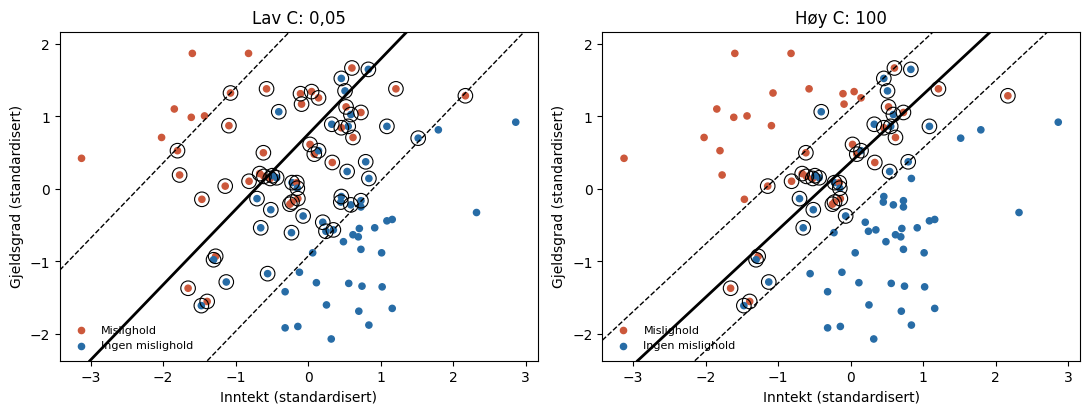

In [5]:
mod_lav = SVC(kernel="linear", C=0.05).fit(X_std, y)   # Billige brudd: forventer bred margin
mod_hoy = SVC(kernel="linear", C=100).fit(X_std, y)    # Dyre brudd: forventer smal margin

fig, akser = plt.subplots(1, 2, figsize=(11, 5))   # To plott ved siden av hverandre
tegn_svc(mod_lav, X_std, y, akser[0], "Lav C: 0,05")
tegn_svc(mod_hoy, X_std, y, akser[1], "Høy C: 100")
plt.tight_layout()
plt.show()

**Slik leser du figuren:**
Heltrukken linje er beslutningsgrensen: søknader på den ene siden klassifiseres som mislighold, på den andre som ikke mislighold.
De stiplede linjene er marginene.
Punkter med ring er støttevektorer: de ligger på marginen, innenfor den eller på feil side av grensen.
Punkter uten ring ligger utenfor marginen på riktig side og påvirker ikke grensen i det hele tatt.

Med lav `C` (venstre) er marginen bred, og mange punkter er støttevektorer.
Med høy `C` (høyre) er marginen smal, og færre punkter bestemmer hvor grensen går.
Legg også merke til at grensen ikke ligger på samme sted i de to panelene: valget av `C` endrer selve klassifikasjonsregelen.

Først en kontroll: gir vår utregning $\boldsymbol\beta = \sum_i \alpha_i x_i$ det samme som `coef_`?

In [6]:
beta_selv = (mod_hoy.dual_coef_ @ mod_hoy.support_vectors_).ravel()
print("Utregnet selv:   ", beta_selv.round(4))
print("Fra mod.coef_:   ", mod_hoy.coef_.ravel().round(4))

Utregnet selv:    [-1.2668  1.359 ]
Fra mod.coef_:    [-1.2668  1.359 ]


De to er like.

Nå oppsummerer vi de to modellene i en tabell.
Marginbredden måles fra den ene stiplede linjen til den andre.
Hver side av grensen har bredde $1/\lVert\boldsymbol\beta\rVert$, så hele marginen er $2/\lVert\boldsymbol\beta\rVert$.

In [7]:
def marginbredde(mod):
    beta = (mod.dual_coef_ @ mod.support_vectors_).ravel()   # Samme utregning av beta som i tegn_svc()
    return 2 / np.linalg.norm(beta)                          # 2 / ||beta||


modeller = {"Lav C": mod_lav, "Høy C": mod_hoy}
pd.DataFrame({
    "antall_stottevektorer": [m.n_support_.sum() for m in modeller.values()],   # Summen over de to klassene
    "marginbredde": [round(marginbredde(m), 2) for m in modeller.values()],
    # predict() gir predikert klasse. != gir True ved feil, og mean() av True/False er andelen feil
    "treningsfeil": [np.mean(m.predict(X_std) != y) for m in modeller.values()],
}, index=modeller.keys())

,antall_stottevektorer,marginbredde,treningsfeil
Lav C,66,2.33,0.21
Høy C,45,1.08,0.21


**Slik leser du output:**
Modellen med lav `C` har 66 støttevektorer og en margin på 2,33 standardavvik.
Modellen med høy `C` har 45 støttevektorer og en margin på 1,08, altså omtrent halvparten så bred.
Begge feilklassifiserer 21 % av treningsdataene.

Treningsfeilen skiller altså ikke mellom modellene, men de er likevel svært forskjellige.
Modellen med høy `C` hviler på færre punkter og vil endre seg mer om dataene endres litt: den har høyere varians.
For å avgjøre hvilken som predikerer best på *nye* søknader, trenger vi data modellen ikke har sett.

## 4. Velg `C` med kryssvalidering

Nå gjør vi det på ordentlig.
Først deler vi de rå dataene i en treningsdel (70 %) og en testdel (30 %).
Testdelen legger vi til side og rører ikke før helt til slutt.

In [8]:
X_raa = dat_laan[["inntekt", "gjeldsgrad"]].to_numpy()   # Rå, uskalerte prediktorer

# permutation() stokker radnumrene 0, 1, ..., 99 i tilfeldig rekkefølge
id_stokket = np.random.default_rng(91).permutation(n)
id_train, id_test = id_stokket[:70], id_stokket[70:]   # De første 70 til trening, resten til test

X_train, y_train = X_raa[id_train], y[id_train]   # 70 søknader til trening og kryssvalidering
X_test, y_test = X_raa[id_test], y[id_test]       # 30 søknader til testen helt til slutt

I R gjorde `svm(scale = TRUE)` skaleringen inne i modellen.
I `scikit-learn` bygger vi i stedet en **pipeline**: en kjede av steg som alltid kjøres i samme rekkefølge.
Her er stegene (1) standardisering med `StandardScaler()` og (2) en lineær `SVC()`.

Det viktige er at pipelinen behandles som *én* modell.
Når den tilpasses, beregnes gjennomsnitt og standardavvik bare fra dataene den tilpasses på.
Når den predikerer, brukes de samme tallene på de nye dataene.

`GridSearchCV()` gjør det samme som `tune()` i R: den prøver hver `C`-verdi med femfolds kryssvalidering på treningsdelen.

1. Treningsdelen deles i fem like store deler (folder) à 14 søknader.
2. Pipelinen tilpasses på fire folder og testes på den femte. Skaleringen beregnes på nytt hver gang, fra de fire treningsfoldene.
3. Dette gjentas fem ganger, slik at hver fold er testfold én gang.
4. Treffraten gjennomsnittes over de fem foldene.

In [9]:
pipeline = make_pipeline(StandardScaler(), SVC(kernel="linear"))

cv_lin = GridSearchCV(
    pipeline,
    # Rutenettet: «svc__C» betyr parameteren C i steget som heter svc
    param_grid={"svc__C": [0.01, 0.1, 1, 10, 100]},
    # Femfolds kryssvalidering. shuffle=True stokker før oppdeling; random_state gjør det reproduserbart
    cv=KFold(n_splits=5, shuffle=True, random_state=92),
)
cv_lin.fit(X_train, y_train)

# GridSearchCV rapporterer treffrate (andel riktige). CV-feil = 1 - treffrate
resultater = pd.DataFrame({
    "C": cv_lin.cv_results_["param_svc__C"],
    "error": 1 - cv_lin.cv_results_["mean_test_score"],
    "dispersion": cv_lin.cv_results_["std_test_score"],
})
resultater

,C,error,dispersion
0,0.01,0.400000,0.085714
1,0.10,0.185714,0.085714
2,1.00,0.214286,0.090351
3,10.00,0.214286,0.063888
4,100.00,0.214286,0.063888


**Slik leser du output:**
Hver rad er én `C`-verdi.
Kolonnene er laget for å ligne `summary(tune(...))$performances` i R:

- `error` er gjennomsnittlig feilklassifiseringsrate over de fem valideringsfoldene (CV-feil).
- `dispersion` er standardavviket i feilraten over foldene, altså et mål på usikkerheten. (Python deler på 5, R på 4, så R-tallet blir litt større.)

`C = 0,01` er tydelig dårligst: CV-feilen er 0,40, som er nøyaktig andelen mislighold.
Marginen blir så bred at modellen sier «Ingen mislighold» til alle.
Fra `C = 0,1` og oppover ligger feilraten mellom 19 % og 21 %.
Forskjellene er små sammenlignet med `dispersion` (rundt 0,06–0,09).
Forskjellen på 0,029 mellom de to beste svarer til bare to av de 70 søknadene.

In [10]:
print(cv_lin.best_params_)

{'svc__C': 0.1}


**Slik leser du output:**
`GridSearchCV` velger `C = 0,1`, fordi den har lavest CV-feil.
Som `tune()` har den også tilpasset den valgte pipelinen på nytt på hele treningsdelen.
Når vi bruker `cv_lin.predict()`, er det denne modellen som brukes.

## 5. Én evaluering på testdata

Til slutt bruker vi den valgte modellen på de 30 søknadene modellen aldri har sett.
Pipelinen skalerer testdataene automatisk med gjennomsnitt og standardavvik fra treningsdelen.

In [11]:
pred_lin = cv_lin.predict(X_test)

# Forvekslingsmatrise: rader er faktisk klasse, kolonner er predikert klasse
pd.crosstab(pd.Series(y_test, name="faktisk"), pd.Series(pred_lin, name="predikert"))

predikert,Ingen mislighold,Mislighold
faktisk,,
Ingen mislighold,14,4
Mislighold,3,9


**Slik leser du forvekslingsmatrisen:**
Diagonalen (14 og 9) er riktige klassifikasjoner, og utenfor diagonalen (4 og 3) er feil.

- Av de 18 som *ikke* misligholdt, ble 14 klassifisert riktig. Spesifisiteten er $14/18 \approx 0{,}78$.
- Av de 12 som misligholdt, fanget modellen opp 9. Sensitiviteten er $9/12 = 0{,}75$.
- 3 misligholdere ble ikke oppdaget (falske negative), og 4 gode kunder ble avvist (falske positive).

For en bank koster disse to feiltypene sannsynligvis svært forskjellig.

In [12]:
print(np.mean(pred_lin == y_test))   # Andel riktige: (14 + 9) / 30

0.7666666666666667


**Slik leser du output:**
Testnøyaktigheten er 0,767, altså 23 av 30 riktige.
Til sammenligning ville en regel som alltid sier «Ingen mislighold» truffet $18/30 = 0{,}60$ i testsettet.
Modellen gjør det altså bedre enn det enkleste alternativet.

Husk likevel at testsettet bare har 30 observasjoner, så tallet er usikkert: én observasjon utgjør over 3 prosentpoeng.
Og nå som vi har sett testresultatet, skal vi *ikke* gå tilbake og justere `C` for å få et bedre tall.